# 04 - Modeling and Evaluation

**Goal:** train models to predict `median_house_value` and measure how good they are.

**Input:** `data/processed/housing_features.csv`  |  **Output:** results table in `results/` and charts in `images/`

### Tasks in this notebook
- [x] Separate features (X) from target (y)
- [x] 80/20 train/test split
- [x] Scale features (fit on training data only)
- [x] Baseline, Linear Regression, Decision Tree, Random Forest
- [x] MAE, RMSE, R-squared for each model
- [x] Predicted vs actual, residuals, feature importance
- [x] Conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
IMAGE_DIR = Path('../images')
RESULTS_DIR = Path('../results')
RESULTS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

df = pd.read_csv('../data/processed/housing_features.csv')
print(df.shape)

(19642, 17)


## 1. Features and target

In [2]:
target = 'median_house_value'
X = df.drop(columns=[target])
y = df[target]
print('Features:', X.shape[1], '| Rows:', len(X))
list(X.columns)

Features: 16 | Rows: 19642


['longitude',
 'latitude',
 'housing_median_age',
 'median_income',
 'total_rooms_log',
 'total_bedrooms_log',
 'population_log',
 'households_log',
 'rooms_per_household',
 'bedrooms_per_room',
 'population_per_household',
 'ocean_proximity_<1H OCEAN',
 'ocean_proximity_INLAND',
 'ocean_proximity_ISLAND',
 'ocean_proximity_NEAR BAY',
 'ocean_proximity_NEAR OCEAN']

## 2. Train/test split
The model learns from 80% of the data (**train**) and is graded on the unseen 20% (**test**). `random_state` makes the split repeatable.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (15713, 16) | Test: (3929, 16)


## 3. Scaling (without data leakage)
`StandardScaler` rescales each feature to mean 0 and standard deviation 1. We **fit it on the training data only**, then apply the same numbers to the test data. Fitting on all the data would leak test information into training.

In [4]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print('Train means (should be ~0):', X_train_s.mean().abs().max().round(6))

Train means (should be ~0): 0.0


## 4. Metrics, including one calculated by hand with NumPy
- **MAE:** average absolute mistake in dollars
- **RMSE:** like MAE but punishes big mistakes more
- **R-squared:** share of price variation explained (1 is perfect, 0 is no better than guessing the average)

In [5]:
def evaluate(name, model, X_tr, X_te):
    pred = model.predict(X_te)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    return {'model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2}, pred

# Practice: compute the same metrics by hand with NumPy on a tiny example
actual = np.array([100.0, 200.0, 300.0])
guess = np.array([110.0, 190.0, 330.0])
print('MAE by hand :', np.mean(np.abs(actual - guess)))
print('RMSE by hand:', np.sqrt(np.mean((actual - guess) ** 2)))

MAE by hand : 16.666666666666668
RMSE by hand: 19.148542155126762


## 5. Train the models
The **baseline** always predicts the training average. Any real model must beat it.

In [6]:
models = {
    'Baseline (mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),
}

rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    row, pred = evaluate(name, model, X_train_s, X_test_s)
    rows.append(row)
    preds[name] = pred
    print(f'trained: {name}')

results = pd.DataFrame(rows).set_index('model').round(3)
results

trained: Baseline (mean)
trained: Linear Regression


trained: Decision Tree


trained: Random Forest


,MAE,RMSE,R2
model,,,
Baseline (mean),78808.685,97744.236,-0.000
Linear Regression,44499.465,61498.099,0.604
Decision Tree,38112.562,55629.924,0.676
Random Forest,30900.001,46556.580,0.773


## 6. Compare the models

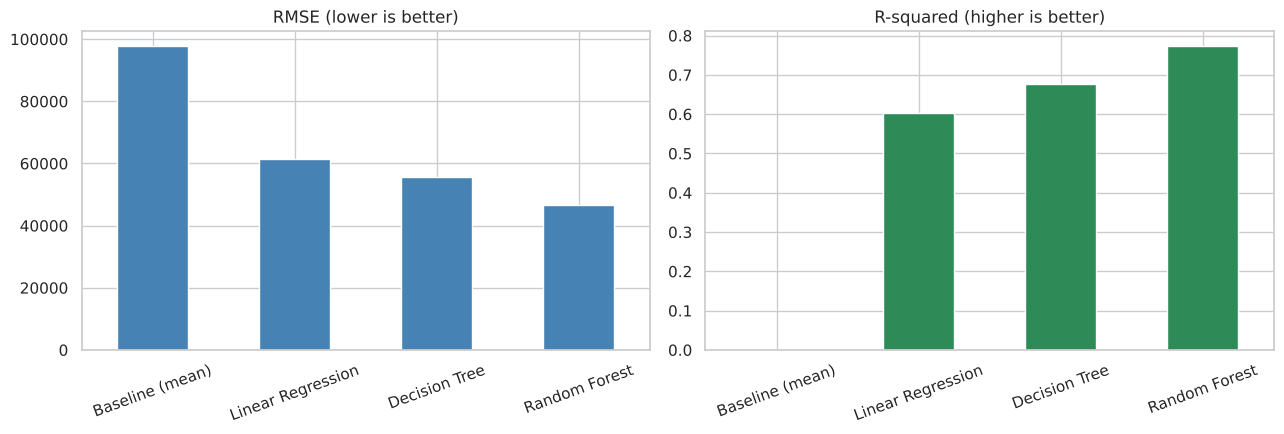

In [7]:
results.to_csv(RESULTS_DIR / 'model_results.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
results['RMSE'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('RMSE (lower is better)')
axes[0].tick_params(axis='x', rotation=20)
results['R2'].plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('R-squared (higher is better)')
axes[1].tick_params(axis='x', rotation=20)
for ax in axes:
    ax.set_xlabel('')
plt.tight_layout()
plt.savefig(IMAGE_DIR / '08_model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Predicted vs actual (best model)
Points on the red diagonal are perfect predictions.

Best model: Random Forest


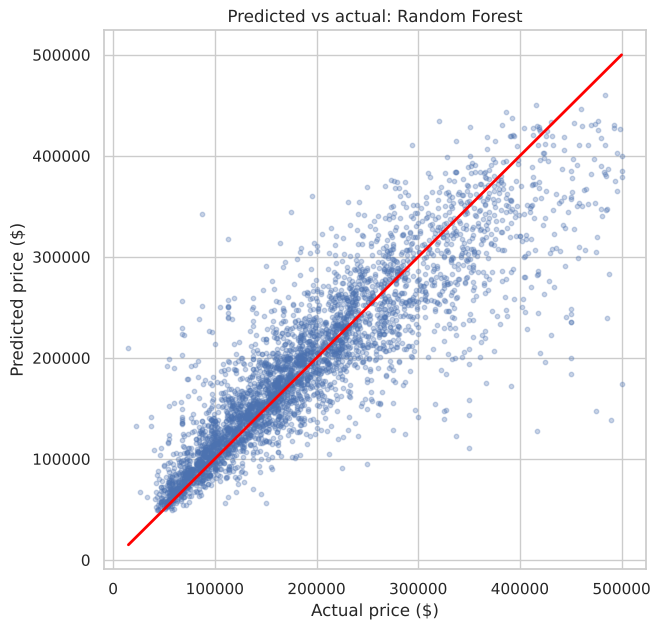

In [8]:
best_name = results['R2'].idxmax()
best_pred = preds[best_name]
print('Best model:', best_name)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_pred, alpha=0.3, s=10)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color='red', linewidth=2)
plt.xlabel('Actual price ($)')
plt.ylabel('Predicted price ($)')
plt.title(f'Predicted vs actual: {best_name}')
plt.savefig(IMAGE_DIR / '09_predicted_vs_actual.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Residuals
Residual = actual minus predicted. Good models have residuals centered on 0 with no clear pattern.

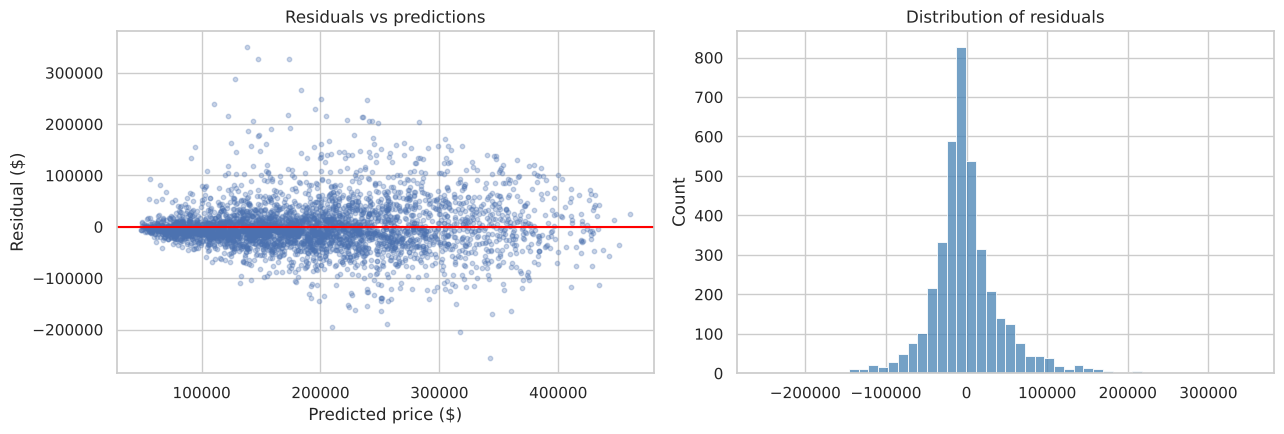

Mean residual: -223  |  Std: 46,556


In [9]:
residuals = y_test.to_numpy() - best_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(best_pred, residuals, alpha=0.3, s=10)
axes[0].axhline(0, color='red')
axes[0].set_xlabel('Predicted price ($)')
axes[0].set_ylabel('Residual ($)')
axes[0].set_title('Residuals vs predictions')
sns.histplot(residuals, bins=50, ax=axes[1], color='steelblue')
axes[1].set_title('Distribution of residuals')
plt.tight_layout()
plt.savefig(IMAGE_DIR / '10_residuals.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Mean residual: {residuals.mean():,.0f}  |  Std: {residuals.std():,.0f}')

## 9. Which features matter most? (Random Forest)

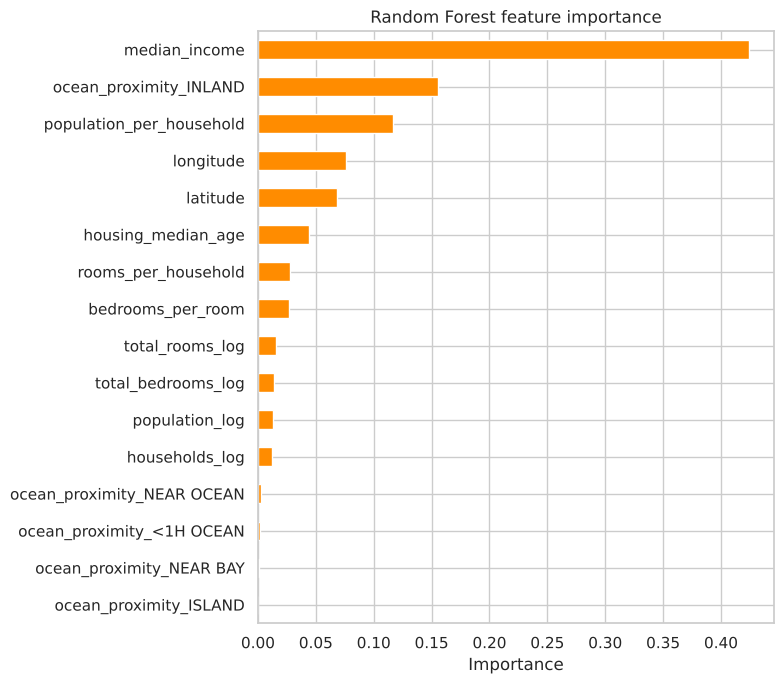

median_income               0.425
ocean_proximity_INLAND      0.156
population_per_household    0.117
longitude                   0.076
latitude                    0.068
dtype: float64

In [10]:
rf = models['Random Forest']
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 7))
importance.plot(kind='barh', color='darkorange')
plt.title('Random Forest feature importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig(IMAGE_DIR / '11_feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

importance.sort_values(ascending=False).head(5).round(3)

## 10. Try a prediction yourself
Pick any row from the test set and compare the prediction with the real price.

In [11]:
i = 0
sample = X_test_s.iloc[[i]]
actual_price = y_test.iloc[i]
predicted_price = models[best_name].predict(sample)[0]
print(f'Actual: ${actual_price:,.0f}  |  Predicted ({best_name}): ${predicted_price:,.0f}')

Actual: $169,900  |  Predicted (Random Forest): $134,481


## 11. Conclusion

In [12]:
base = results.loc['Baseline (mean)']
best = results.loc[best_name]
print(f'Best model: {best_name}')
print(f'  R2   : {best.R2:.3f}  (baseline {base.R2:.3f})')
print(f'  MAE  : ${best.MAE:,.0f}  (baseline ${base.MAE:,.0f})')
print(f'  RMSE : ${best.RMSE:,.0f}  (baseline ${base.RMSE:,.0f})')
print(f'On average the best model is off by about ${best.MAE:,.0f} per block group.')

Best model: Random Forest
  R2   : 0.773  (baseline -0.000)
  MAE  : $30,900  (baseline $78,809)
  RMSE : $46,557  (baseline $97,744)
On average the best model is off by about $30,900 per block group.


**Your turn:** write your own conclusion here for your README. Cover:
1. Which model won, and why do you think it beat the others?
2. Which features mattered most, and does that match what you saw in notebook 01?
3. Where does the model make its biggest mistakes (look at the residual plots)?
4. What would you try next (tuning, other models, more features)?

## 12. Check your work

In [13]:
assert (RESULTS_DIR / 'model_results.csv').exists()
assert results.loc['Random Forest', 'R2'] > results.loc['Linear Regression', 'R2'] > results.loc['Baseline (mean)', 'R2'] - 1e-9, \
    'Expected Random Forest > Linear Regression > Baseline'
assert results.loc['Random Forest', 'R2'] > 0.7, 'Random Forest R2 should be above 0.7'
assert abs(results.loc['Baseline (mean)', 'R2']) < 0.01, 'Baseline R2 should be near 0'
print('Notebook 04 checks passed. Project complete!')

Notebook 04 checks passed. Project complete!
